1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Exportación completada (N = 70; primarios = 54; secundarios (s) = 16)
Archivos guardados en: /Users/joanpau/Documents/00_Inbox/SLR - Results Points/Images/fig_evidence_base_fullpage70.{pdf,png,svg}


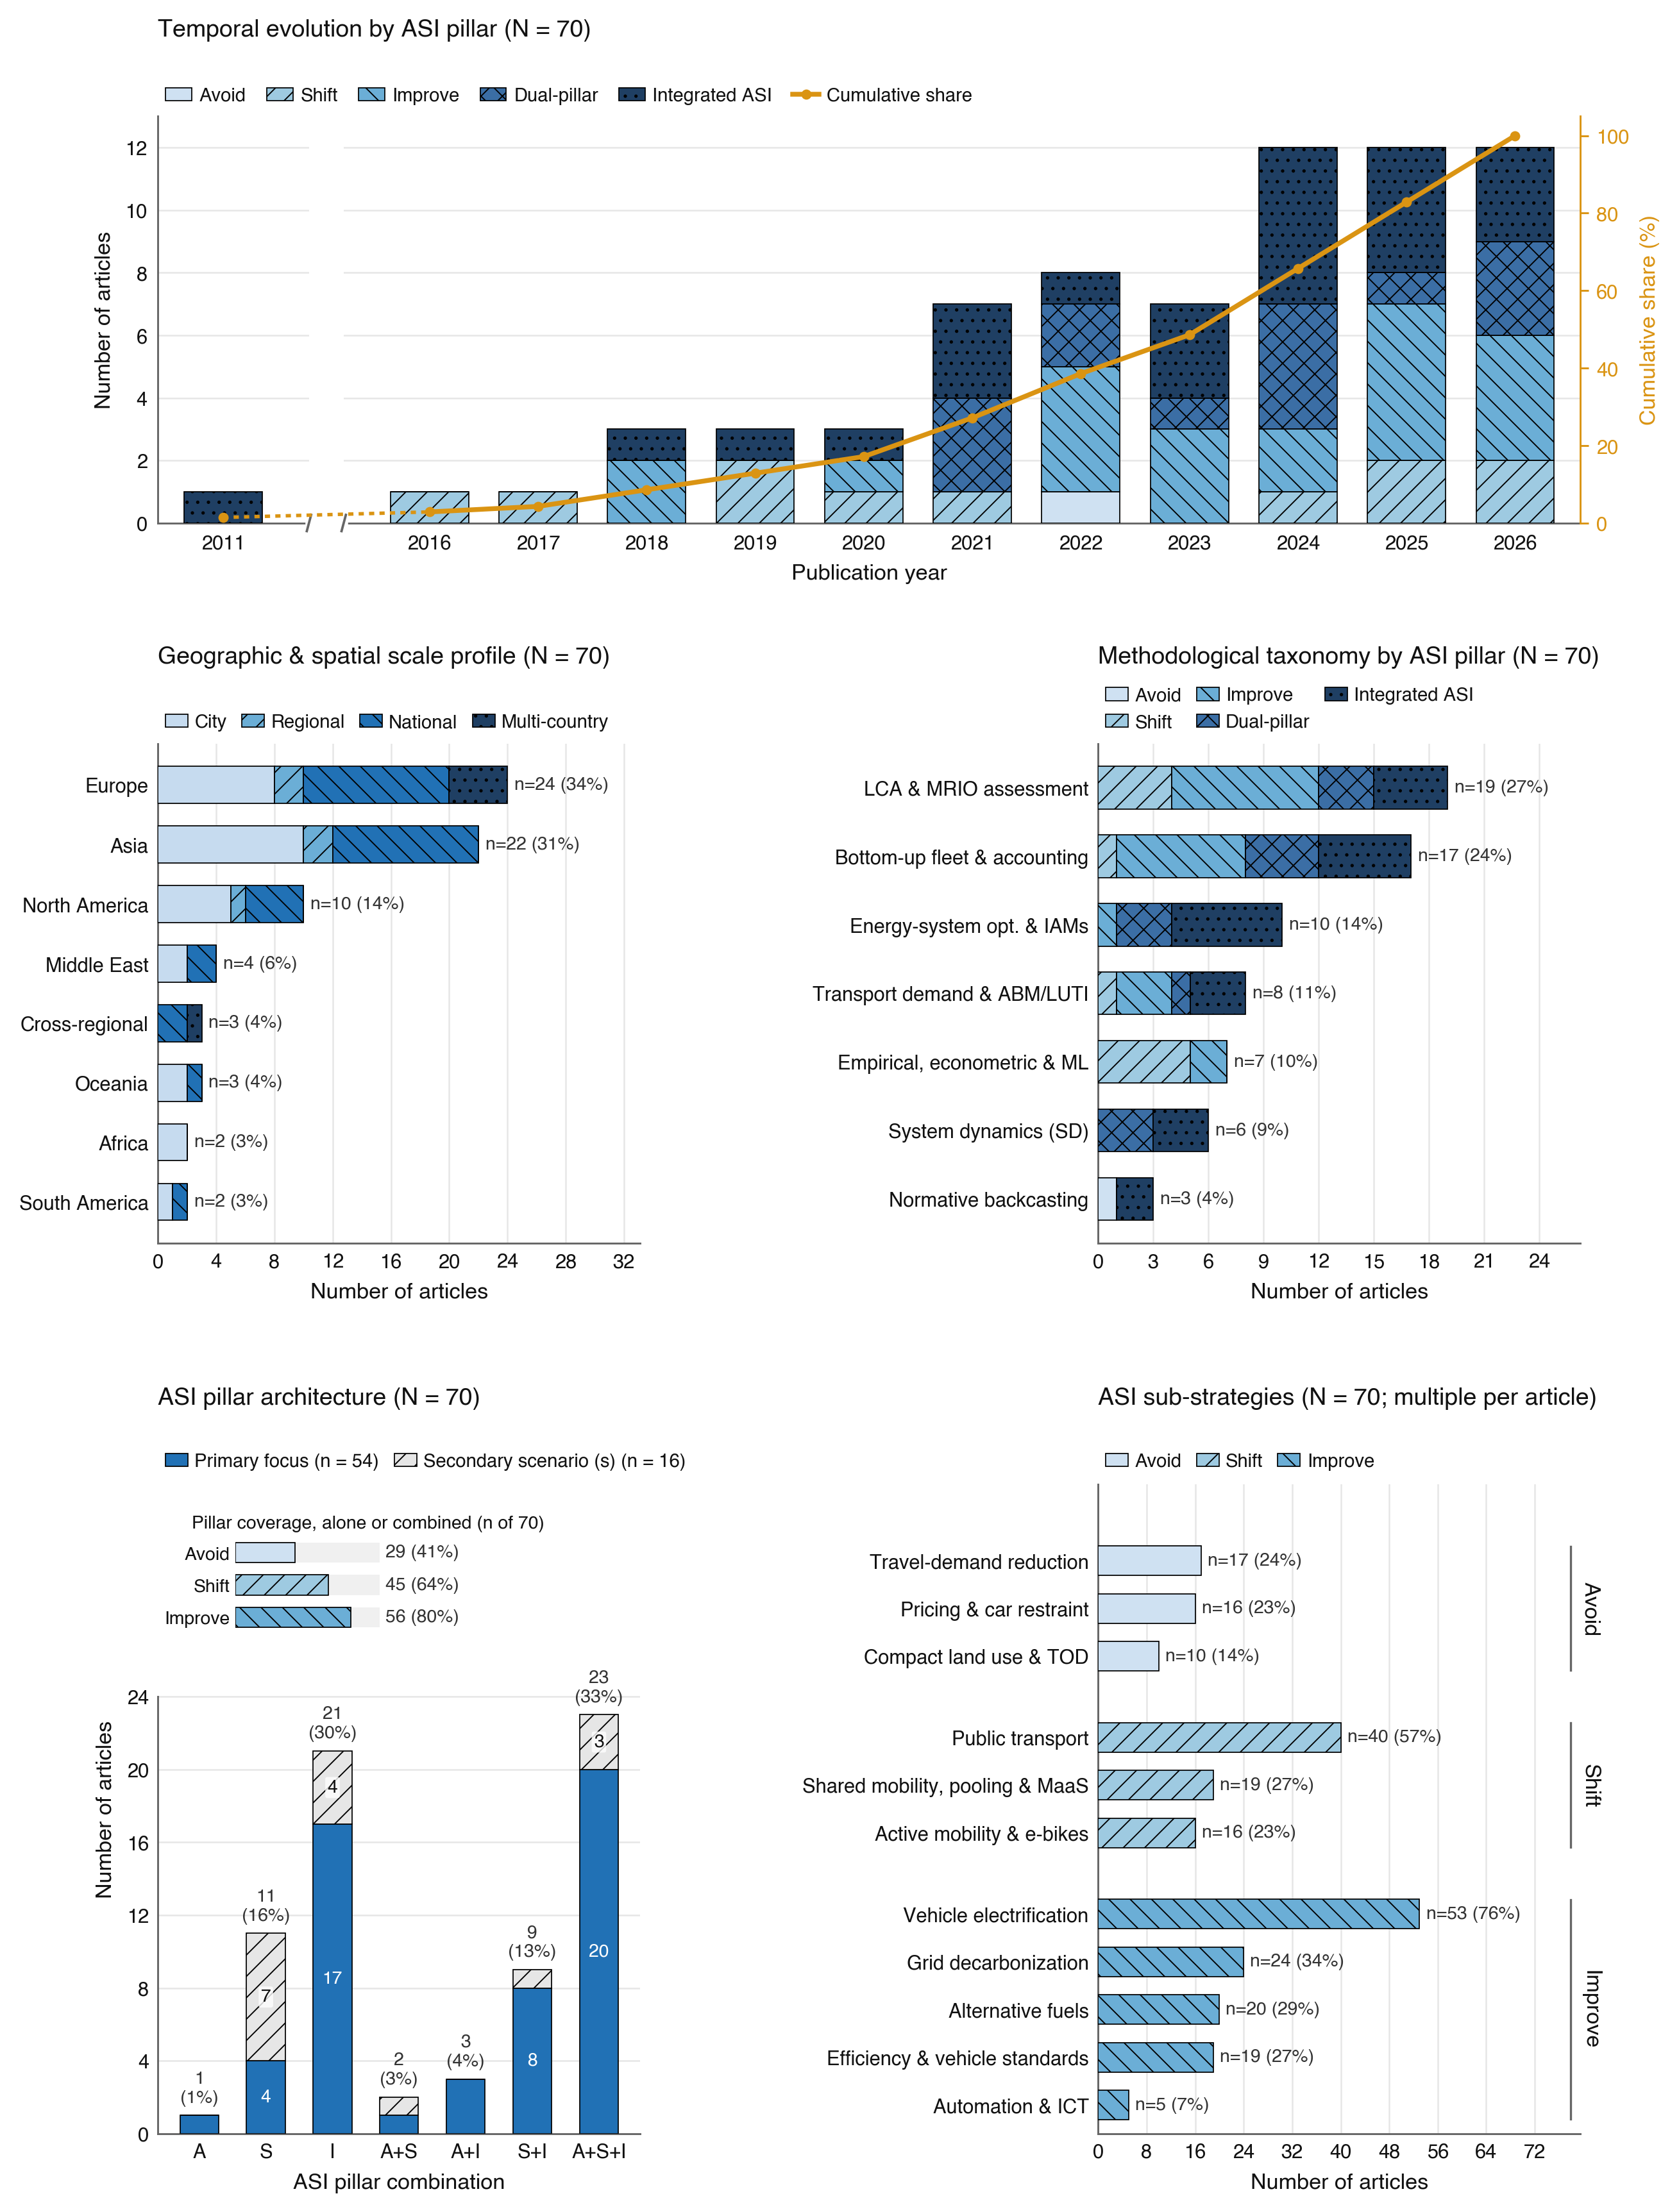

In [1]:
# %% [FIGURA EVIDENCE BASE – PÁGINA COMPLETA] Evolución temporal + geografía + métodos + arquitectura ASI + sub-estrategias (N = 70)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ==============================================================================
# 0. RUTAS Y PARÁMETROS
# ==============================================================================
DARK_MODE = False   # True -> versión sobre negro absoluto (#000000)
FS = 1.0            # Escala de TODAS las fuentes (súbelo para letras más grandes)

# Tamaño pensado para una página A4 completa (\textwidth x ~\textheight menos el caption).
# Se dibuja a 8.4 in de ancho; en LaTeX se escala a 6.3 in (factor 0.75).
FIGSIZE = (8.4, 11.4)

INFILE = Path("/Users/joanpau/Documents/00_Inbox/SLR - Results Points/SLR Extraction Sheet.xlsx")
if not INFILE.exists():
    raise FileNotFoundError(f"No se encontró el archivo en: {INFILE}")

OUTDIR = INFILE.parent / "Images"
OUTDIR.mkdir(exist_ok=True)

df = pd.read_excel(INFILE, sheet_name="Extraction").dropna(subset=["ID"])
df["ID"] = df["ID"].astype(str).str.strip()
df["Year"] = pd.to_numeric(df["Year"], errors="raise").astype(int)
df["Is_secondary"] = df["Author"].astype(str).str.contains(r"\(s\)", regex=True)

N_TOTAL = len(df)
N_PRIM = int((~df["Is_secondary"]).sum())
N_SEC = int(df["Is_secondary"].sum())

# --- Mapeo de pilares ASI ---
ASI_5_ORDER = ["Avoid", "Shift", "Improve", "Dual-pillar", "Integrated ASI"]
PILLAR_5_MAP = {
    "A": "Avoid", "S": "Shift", "I": "Improve",
    "A+S": "Dual-pillar", "A+I": "Dual-pillar", "S+I": "Dual-pillar",
    "A+S+I": "Integrated ASI",
}
df["Pillar_5"] = df["Pillar"].astype(str).str.strip().map(PILLAR_5_MAP)

# --- Taxonomía metodológica completa (S01–S70) ---
METHOD_7_BY_ID = {
    **{k: "Bottom-up fleet & accounting" for k in [
        "S01", "S02", "S08", "S11", "S13", "S14", "S19", "S32", "S34",
        "S35", "S38", "S39", "S43", "S44", "S47", "S57", "S68"
    ]},
    **{k: "LCA & MRIO assessment" for k in [
        "S03", "S07", "S18", "S21", "S24", "S29", "S30", "S33", "S37",
        "S45", "S48", "S55", "S58", "S59", "S60", "S62", "S64", "S65", "S67"
    ]},
    **{k: "Energy-system opt. & IAMs" for k in [
        "S04", "S20", "S23", "S27", "S40", "S49", "S50", "S51", "S63", "S66"
    ]},
    **{k: "Transport demand & ABM/LUTI" for k in [
        "S05", "S22", "S31", "S36", "S42", "S52", "S56", "S61"
    ]},
    **{k: "System dynamics (SD)" for k in [
        "S12", "S15", "S17", "S25", "S53", "S54"
    ]},
    **{k: "Empirical, econometric & ML" for k in [
        "S06", "S09", "S16", "S41", "S46", "S69", "S70"
    ]},
    **{k: "Normative backcasting" for k in [
        "S10", "S26", "S28"
    ]},
}
df["Method_grp"] = df["ID"].map(METHOD_7_BY_ID)

# --- Clasificación geográfica completa (N = 70) ---
def classify_region(val):
    s = str(val).strip()
    if any(k in s for k in ["Netherlands, Sweden", "Brazil, India", "Japan, United Kingdom"]):
        return "Cross-regional"
    if any(k in s for k in ["China", "India", "Japan", "Singapore", "Taiwan", "Southeast Asia"]):
        return "Asia"
    if any(k in s for k in [
        "EU27", "Europe", "European", "Germany", "Hamburg", "Sweden", "UK", "United Kingdom",
        "Ireland", "Portugal", "Latvia", "Spain", "Antwerp", "Austria", "Poland"
    ]):
        return "Europe"
    if any(k in s for k in ["United States", "USA", "Canada", "Mexico"]):
        return "North America"
    if any(k in s for k in ["Qatar", "Iran", "Türkiye"]):
        return "Middle East"
    if any(k in s for k in ["Uganda", "Nigeria"]):
        return "Africa"
    if "Australia" in s:
        return "Oceania"
    if any(k in s for k in ["Argentina", "Colombia"]):
        return "South America"
    return "Other"

df["Region_grp"] = df["Region / country"].apply(classify_region)

# --- Sub-estrategias ASI (multi-etiqueta, codificadas a partir de la columna "Sub-strategy";
#     filas truncadas o erróneas completadas con Title/Notes). Cada estudio cuenta una vez
#     por sub-estrategia. La agrupación por pilar sigue la asignación convencional del marco
#     ASI, con independencia de la etiqueta de pilar del estudio. ---
SUBSTRATEGIES = {
    "A1": ("Avoid",   "Travel-demand reduction"),
    "A2": ("Avoid",   "Compact land use & TOD"),
    "A3": ("Avoid",   "Pricing & car restraint"),
    "S1": ("Shift",   "Public transport"),
    "S2": ("Shift",   "Active mobility & e-bikes"),
    "S3": ("Shift",   "Shared mobility, pooling & MaaS"),
    "I1": ("Improve", "Vehicle electrification"),
    "I2": ("Improve", "Grid decarbonization"),
    "I3": ("Improve", "Alternative fuels"),
    "I4": ("Improve", "Efficiency & vehicle standards"),
    "I5": ("Improve", "Automation & ICT"),
}
SUB_BY_ID = {
    "S01": "A1 S3 I1 I2",          "S02": "I1 I2 I4 I5",          "S03": "A1 S1 S2 S3 I1",
    "S04": "A1 S1 S2 S3 I1",       "S05": "I1 I4",                "S06": "S3",
    "S07": "S1 I1 I2 I3",          "S08": "I1 I2",                "S09": "S2",
    "S10": "A1 A2 S1 S2 I1 I2 I3 I4", "S11": "S1 I1 I3 I4",       "S12": "A1 S1 I1 I2 I3 I4",
    "S13": "A3 I1",                "S14": "A1 S1 I1",             "S15": "S1 S2 I1",
    "S16": "A3 S1 I1 I5",          "S17": "A3 S1",                "S18": "I1 I3",
    "S19": "A3 S1 S2 S3 I3 I4",    "S20": "A1 S1 S2 I1",          "S21": "S3 I1 I2 I3 I4",
    "S22": "I1 I2",                "S23": "I1 I3",                "S24": "S3 I1",
    "S25": "S1 I1 I3",             "S26": "A3 S3",                "S27": "S1 I1",
    "S28": "A1 A2 S1 S2 I1 I2 I3 I5", "S29": "I1 I3",             "S30": "I1 I2 I3 I4",
    "S31": "I1 I2 I5",             "S32": "A1 A2 S1 I4",          "S33": "A1 S1 I1 I2",
    "S34": "I1 I2",                "S35": "I1 I2 I3",             "S36": "A2 A3 S1 I4",
    "S37": "I1 I2 I4",             "S38": "S1 S2",                "S39": "A1 S1 S3 I1 I3 I4",
    "S40": "A3 S1 I1 I3",          "S41": "S1 I1",                "S42": "A1 A3 S1 I1",
    "S43": "I1 I2",                "S44": "A2 A3 S1",             "S45": "I1 I2",
    "S46": "I1 I2 I3",             "S47": "S1 I1 I3 I4",          "S48": "A2 A3 S1 S2 S3 I1 I2 I4",
    "S49": "A3 I1 I3",             "S50": "A1 A2 A3 S1 S3 I1 I3", "S51": "A1 A2 A3 S1 S3 I1 I3",
    "S52": "A2 S1 I1",             "S53": "A3 S1 I1",             "S54": "S1 S2 S3 I1 I4",
    "S55": "S1",                   "S56": "A1 A2 A3 S1 S2 S3",    "S57": "S1 S2 I1 I2 I4",
    "S58": "S1",                   "S59": "S3",                   "S60": "I1 I2",
    "S61": "S2",                   "S62": "A1 S1 S2 S3 I1 I2",    "S63": "A1 S1 S2 S3 I1 I4",
    "S64": "S1",                   "S65": "I1 I2",                "S66": "A3 S1 I1",
    "S67": "I1 I2 I4",             "S68": "I1 I4 I5",             "S69": "S3",
    "S70": "S1 S3",
}

# Aserciones de integridad
assert df["Pillar_5"].isna().sum() == 0, f"Pilares sin mapear: {df[df['Pillar_5'].isna()]['ID'].tolist()}"
assert df["Method_grp"].isna().sum() == 0, f"Métodos sin mapear: {df[df['Method_grp'].isna()]['ID'].tolist()}"
assert (df["Region_grp"] == "Other").sum() == 0, f"Regiones sin mapear: {df[df['Region_grp'] == 'Other']['Region / country'].tolist()}"
assert set(SUB_BY_ID) == set(df["ID"]), f"Sub-estrategias sin codificar: {sorted(set(df['ID']) - set(SUB_BY_ID))}"
assert all(c in SUBSTRATEGIES for v in SUB_BY_ID.values() for c in v.split())

sub_long = pd.DataFrame(
    [(sid, c, *SUBSTRATEGIES[c]) for sid, v in SUB_BY_ID.items() for c in v.split()],
    columns=["ID", "Code", "Sub_pillar", "Sub_strategy"],
).merge(df[["ID", "Author", "Year", "Pillar", "Pillar_5", "Sub-strategy"]], on="ID")

# ==============================================================================
# 1. PALETAS Y TIPOGRAFÍA EDITORIAL (LIGHT / DARK)
# ==============================================================================
BG_COL    = "#000000" if DARK_MODE else "#FFFFFF"
FG_COL    = "#FFFFFF" if DARK_MODE else "#111111"
SUB_COL   = "#D9D9D9" if DARK_MODE else "#333333"
EDGE_COL  = "#FFFFFF" if DARK_MODE else "#000000"
GRID_COL  = "#222222" if DARK_MODE else "0.90"
SPINE_COL = "#888888" if DARK_MODE else "0.40"
CUM_COL   = "#f2be54" if DARK_MODE else "#da9413"   # oro del paper (cuota acumulada)

ASI_5_COLORS = dict(zip(
    ASI_5_ORDER,
    ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#2b5c8f" if DARK_MODE else "#1f3f63"]
))
ASI_5_HATCHES = dict(zip(ASI_5_ORDER, ["", "///", "\\\\\\", "xxx", "..."]))

SCALE_ORDER = ["City", "Regional", "National", "Multi-country"]
SCALE_COLORS = {
    "City":          "#c6dbef",
    "Regional":      "#6baed6",
    "National":      "#2171b5",
    "Multi-country": "#2b5c8f" if DARK_MODE else "#1f3f63",
}
SCALE_HATCHES = {"City": "", "Regional": "///", "National": "\\\\\\", "Multi-country": "..."}

# Tamaños de letra (todos escalan con FS)
F_TITLE, F_LABEL, F_TICK, F_LEG, F_ANN = 9.0 * FS, 8.2 * FS, 7.4 * FS, 7.0 * FS, 6.8 * FS
TITLE_PAD = 30 * FS

plt.rcParams.update({
    "font.family":       "sans-serif",
    "font.sans-serif":   ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size":         F_TICK,
    "axes.labelsize":    F_LABEL,
    "axes.titlesize":    F_TITLE,
    "xtick.labelsize":   F_TICK,
    "ytick.labelsize":   F_TICK,
    "legend.fontsize":   F_LEG,
    "axes.linewidth":    0.7,
    "hatch.linewidth":   0.45,
    "hatch.color":       EDGE_COL,
    "figure.facecolor":  BG_COL,
    "axes.facecolor":    BG_COL,
    "savefig.facecolor": BG_COL,
    "text.color":        FG_COL,
    "axes.labelcolor":   FG_COL,
    "xtick.color":       FG_COL,
    "ytick.color":       FG_COL,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
})

def style_ax(ax, grid_axis="y"):
    ax.set_facecolor(BG_COL)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(SPINE_COL)
    ax.spines["bottom"].set_color(SPINE_COL)
    if grid_axis == "y":
        ax.yaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    elif grid_axis == "x":
        ax.xaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=FG_COL)

def style_legend(leg):
    for patch in leg.get_patches():
        patch.set_linewidth(0.42)
        patch.set_edgecolor(EDGE_COL)

def panel_title(ax, text):
    ax.set_title(text, fontsize=F_TITLE, fontweight="bold", pad=TITLE_PAD, loc="left", color=FG_COL)

def top_legend(ax, ncol, **kw):
    leg = ax.legend(ncol=ncol, frameon=False, fontsize=F_LEG, handlelength=1.2,
                    columnspacing=0.8, handletextpad=0.35, labelcolor=FG_COL,
                    loc="lower left", bbox_to_anchor=(0.0, 1.01), borderaxespad=0, **kw)
    style_legend(leg)
    return leg

# ==============================================================================
# 2. MAQUETACIÓN: fila superior a todo el ancho + rejilla 2x2
# ==============================================================================
fig = plt.figure(figsize=FIGSIZE, dpi=300, facecolor=BG_COL)
outer = gridspec.GridSpec(3, 1, figure=fig, height_ratios=[0.80, 1.0, 1.30], hspace=0.42,
                          left=0.06, right=0.94, top=0.97, bottom=0.05)
ax_t = fig.add_subplot(outer[0])
grid = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=outer[1:], height_ratios=[1.0, 1.30],
                                        hspace=0.42, wspace=0.95)
ax_a = fig.add_subplot(grid[0, 0])
ax_b = fig.add_subplot(grid[0, 1])
ax_c = fig.add_subplot(grid[1, 0])
ax_d = fig.add_subplot(grid[1, 1])

# ------------------------------------------------------------------------------
# PANEL SUPERIOR: Evolución temporal por pilar ASI + cuota acumulada (eje con corte)
# ------------------------------------------------------------------------------
BREAK_YEARS = range(2012, 2016)   # años sin publicaciones que se omiten
GAP = 0.9                         # anchura del hueco del corte (en "años" de eje)

yr0, yr1 = int(df["Year"].min()), int(df["Year"].max())
M_year = (pd.crosstab(df["Year"], df["Pillar_5"])
            .reindex(columns=ASI_5_ORDER, fill_value=0)
            .reindex(range(yr0, yr1 + 1), fill_value=0))
total_per_year = M_year.sum(axis=1)
cum_share = 100 * total_per_year.cumsum() / total_per_year.sum()
assert total_per_year.reindex(BREAK_YEARS, fill_value=0).sum() == 0, "BREAK_YEARS contiene publicaciones"

years = [y for y in M_year.index if y not in BREAK_YEARS]
x_t = np.arange(len(years), dtype=float)
x_t[np.array(years) > max(BREAK_YEARS)] += GAP
M_year, total_per_year, cum_share = M_year.loc[years], total_per_year.loc[years], cum_share.loc[years]
i_before = years.index(min(BREAK_YEARS) - 1)
x_break = (x_t[i_before] + x_t[i_before + 1]) / 2

bottom_t = np.zeros(len(years))
for p in ASI_5_ORDER:
    vals = M_year[p].values
    ax_t.bar(x_t, vals, bottom=bottom_t, width=0.72, label=p, color=ASI_5_COLORS[p],
             edgecolor=EDGE_COL, linewidth=0.42, hatch=ASI_5_HATCHES[p], zorder=3)
    bottom_t += vals

ax_t.set_ylabel("Number of articles", fontsize=F_LABEL)
ax_t.set_xlabel("Publication year", fontsize=F_LABEL)
ax_t.set_xticks(x_t)
ax_t.set_xticklabels([str(y) for y in years])
ax_t.yaxis.set_major_locator(MaxNLocator(integer=True))
ax_t.set_ylim(0, total_per_year.max() + 1)
ax_t.set_xlim(x_t[0] - 0.6, x_t[-1] + 0.6)
style_ax(ax_t, grid_axis="y")
ax_t.tick_params(pad=4)
panel_title(ax_t, f"Temporal evolution by ASI pillar (N = {N_TOTAL})")

# Marca de corte (//) en el eje X
half = 0.16
trans = ax_t.get_xaxis_transform()
ax_t.axvspan(x_break - half, x_break + half, color=BG_COL, zorder=1, linewidth=0)
ax_t.plot([x_break - half, x_break + half], [0, 0], color=BG_COL, linewidth=3,
          transform=trans, clip_on=False, zorder=5)
for dx in (-half, half):
    ax_t.plot([x_break + dx - 0.02, x_break + dx + 0.02], [-0.02, 0.02], color=SPINE_COL,
              linewidth=0.9, transform=trans, clip_on=False, zorder=6)

# Eje derecho: cuota acumulada
ax_t2 = ax_t.twinx()
pre, post = slice(0, i_before + 1), slice(i_before + 1, None)
kw = dict(color=CUM_COL, linewidth=1.8, zorder=4)
ax_t2.plot(x_t[pre], cum_share.values[pre], **kw)
ax_t2.plot(x_t[post], cum_share.values[post], **kw)
ax_t2.plot(x_t[i_before:i_before + 2], cum_share.values[i_before:i_before + 2], color=CUM_COL,
           linewidth=1.3, linestyle=(0, (1.5, 1.5)), zorder=4)
ax_t2.plot(x_t, cum_share.values, linestyle="none", marker="o", markersize=3.8, color=CUM_COL,
           markeredgewidth=0, zorder=5)
ax_t2.set_ylim(0, 105)
ax_t2.set_yticks(range(0, 101, 20))
ax_t2.set_ylabel("Cumulative share (%)", fontsize=F_LABEL, color=CUM_COL)
ax_t2.tick_params(axis="y", labelsize=F_TICK, direction="out", length=3, width=0.7, pad=3,
                  colors=CUM_COL)
for s in ["top", "left", "bottom"]:
    ax_t2.spines[s].set_visible(False)
ax_t2.spines["right"].set_color(CUM_COL)

handles_t, labels_t = ax_t.get_legend_handles_labels()
handles_t.append(Line2D([0], [0], color=CUM_COL, linewidth=1.8, marker="o", markersize=3.8,
                        markeredgewidth=0))
labels_t.append("Cumulative share")
leg_t = ax_t.legend(handles_t, labels_t, ncol=len(labels_t), frameon=False, fontsize=F_LEG,
                    handlelength=1.4, handletextpad=0.4, columnspacing=1.1, labelcolor=FG_COL,
                    loc="lower left", bbox_to_anchor=(0.0, 1.01), borderaxespad=0)
style_legend(leg_t)

# ------------------------------------------------------------------------------
# PANEL: Perfil geográfico y escala espacial
# ------------------------------------------------------------------------------
reg_order = df["Region_grp"].value_counts().index.tolist()[::-1]
M_geo = (pd.crosstab(df["Region_grp"], df["Scale"].astype(str).str.strip())
           .reindex(index=reg_order, columns=SCALE_ORDER, fill_value=0))

y_geo = np.arange(len(reg_order))
left_a = np.zeros(len(reg_order))
for sc in SCALE_ORDER:
    vals = M_geo[sc].values
    ax_a.barh(y_geo, vals, left=left_a, height=0.62, color=SCALE_COLORS[sc], edgecolor=EDGE_COL,
              linewidth=0.42, hatch=SCALE_HATCHES[sc], label=sc, zorder=3)
    left_a += vals
for yi, tot in enumerate(left_a):
    ax_a.text(tot + max(left_a) * 0.02, yi, f"n={int(tot)} ({100 * tot / N_TOTAL:.0f}%)",
              va="center", ha="left", fontsize=F_ANN, color=SUB_COL)

ax_a.set_yticks(y_geo)
ax_a.set_yticklabels(reg_order, fontweight="bold")
ax_a.set_xlabel("Number of articles", fontsize=F_LABEL)
ax_a.set_xlim(0, max(left_a) * 1.38)
ax_a.xaxis.set_major_locator(MaxNLocator(integer=True))
style_ax(ax_a, grid_axis="x")
panel_title(ax_a, f"Geographic & spatial scale profile (N = {N_TOTAL})")
top_legend(ax_a, ncol=4)

# ------------------------------------------------------------------------------
# PANEL: Taxonomía metodológica por pilar ASI
# ------------------------------------------------------------------------------
meth_order = df["Method_grp"].value_counts().index.tolist()[::-1]
M_meth = (pd.crosstab(df["Method_grp"], df["Pillar_5"])
            .reindex(index=meth_order, columns=ASI_5_ORDER, fill_value=0))

y_meth = np.arange(len(meth_order))
left_b = np.zeros(len(meth_order))
for p in ASI_5_ORDER:
    vals = M_meth[p].values
    ax_b.barh(y_meth, vals, left=left_b, height=0.62, color=ASI_5_COLORS[p], edgecolor=EDGE_COL,
              linewidth=0.42, hatch=ASI_5_HATCHES[p], label=p, zorder=3)
    left_b += vals
for yi, tot in enumerate(left_b):
    ax_b.text(tot + max(left_b) * 0.02, yi, f"n={int(tot)} ({100 * tot / N_TOTAL:.0f}%)",
              va="center", ha="left", fontsize=F_ANN, color=SUB_COL)

ax_b.set_yticks(y_meth)
ax_b.set_yticklabels(meth_order, fontweight="bold")
ax_b.set_xlabel("Number of articles", fontsize=F_LABEL)
ax_b.set_xlim(0, max(left_b) * 1.38)
ax_b.xaxis.set_major_locator(MaxNLocator(integer=True))
style_ax(ax_b, grid_axis="x")
panel_title(ax_b, f"Methodological taxonomy by ASI pillar (N = {N_TOTAL})")
top_legend(ax_b, ncol=3)

# ------------------------------------------------------------------------------
# PANEL: Arquitectura de combinaciones de pilares ASI (búsqueda primaria vs (s))
# ------------------------------------------------------------------------------
PILLAR_7_ORDER = ["A", "S", "I", "A+S", "A+I", "S+I", "A+S+I"]
pill = df["Pillar"].astype(str).str.strip()
prim_counts = pill[~df["Is_secondary"]].value_counts().reindex(PILLAR_7_ORDER, fill_value=0).values
sec_counts  = pill[df["Is_secondary"]].value_counts().reindex(PILLAR_7_ORDER, fill_value=0).values

x_p7 = np.arange(len(PILLAR_7_ORDER))
col_prim_c = "#2b7bba" if DARK_MODE else "#2171b5"
col_sec_c  = "#262626" if DARK_MODE else "#e6e6e6"

ax_c.bar(x_p7, prim_counts, width=0.58, color=col_prim_c, edgecolor=EDGE_COL,
         linewidth=0.42, label=f"Primary focus (n = {N_PRIM})", zorder=3)
ax_c.bar(x_p7, sec_counts, bottom=prim_counts, width=0.58, color=col_sec_c,
         edgecolor=EDGE_COL, linewidth=0.42, hatch="///",
         label=f"Secondary scenario (s) (n = {N_SEC})", zorder=3)

totals_c = prim_counts + sec_counts
for xi, (pr, sc, tot) in enumerate(zip(prim_counts, sec_counts, totals_c)):
    ax_c.text(xi, tot + max(totals_c) * 0.022, f"{tot}\n({100 * tot / N_TOTAL:.0f}%)",
              ha="center", va="bottom", fontsize=F_ANN, fontweight="bold", color=SUB_COL)
    if pr >= 3 and sc > 0:
        ax_c.text(xi, pr / 2, f"{pr}", ha="center", va="center",
                  fontsize=F_ANN, fontweight="bold", color="#FFFFFF", zorder=4)
    if sc >= 3:
        ax_c.text(xi, pr + sc / 2, f"{sc}", ha="center", va="center",
                  fontsize=F_ANN, fontweight="bold", color=FG_COL, zorder=4,
                  bbox=dict(boxstyle="round,pad=0.12", facecolor=BG_COL, edgecolor="none", alpha=0.8))

ax_c.set_xticks(x_p7)
ax_c.set_xticklabels(PILLAR_7_ORDER, fontweight="bold")
ax_c.set_xlabel("ASI pillar combination", fontsize=F_LABEL)
ax_c.set_ylabel("Number of articles", fontsize=F_LABEL)
ax_c.set_ylim(0, max(totals_c) * 1.55)
y_top_c = int(np.ceil(max(totals_c) / 4) * 4)               # último tick útil (24)
ax_c.set_yticks(range(0, y_top_c + 1, 4))
style_ax(ax_c, grid_axis="y")
ax_c.spines["left"].set_bounds(0, y_top_c)                  # eje y acotado: deja libre el recuadro
panel_title(ax_c, f"ASI pillar architecture (N = {N_TOTAL})")
top_legend(ax_c, ncol=2)

# Recuadro de cobertura: artículos que evalúan cada pilar, solo o combinado (barra sobre N total)
pillar_any = {p: int(pill.str.contains(p[0]).sum()) for p in ["Avoid", "Shift", "Improve"]}
TRACK_COL = "#1a1a1a" if DARK_MODE else "#f0f0f0"
ax_in = ax_c.inset_axes([0.16, 0.77, 0.30, 0.15])
for i, (p, n) in enumerate(list(pillar_any.items())[::-1]):
    ax_in.barh(i, N_TOTAL, height=0.62, color=TRACK_COL, edgecolor="none", zorder=1)
    ax_in.barh(i, n, height=0.62, color=ASI_5_COLORS[p], edgecolor=EDGE_COL, linewidth=0.42,
               hatch=ASI_5_HATCHES[p], zorder=2)
    ax_in.text(N_TOTAL * 1.04, i, f"{n} ({100 * n / N_TOTAL:.0f}%)", va="center", ha="left",
               fontsize=F_ANN, color=SUB_COL)
ax_in.set_yticks(range(3))
ax_in.set_yticklabels(list(pillar_any)[::-1], fontsize=F_ANN, color=FG_COL)
ax_in.set_xlim(0, N_TOTAL)
ax_in.set_ylim(-0.5, 2.5)
ax_in.set_xticks([])
ax_in.tick_params(length=0, pad=2)
for s in ax_in.spines.values():
    s.set_visible(False)
ax_in.set_facecolor("none")
ax_in.set_title(f"Pillar coverage, alone or combined (n of {N_TOTAL})", fontsize=F_ANN,
                color=FG_COL, loc="left", pad=3, x=-0.30)

# ------------------------------------------------------------------------------
# PANEL: Sub-estrategias ASI (artículos que evalúan cada sub-estrategia)
# ------------------------------------------------------------------------------
SUB_PILLARS = ["Avoid", "Shift", "Improve"]
sub_counts = sub_long.groupby("Code")["ID"].nunique()

rows, y_pos, y = [], [], 0.0
group_spans = {}
for gp in SUB_PILLARS[::-1]:                       # Improve abajo, Avoid arriba
    codes = sorted([c for c, (p, _) in SUBSTRATEGIES.items() if p == gp],
                   key=lambda c: sub_counts.get(c, 0))
    start = y
    for c in codes:
        rows.append(c)
        y_pos.append(y)
        y += 1.0
    group_spans[gp] = (start, y - 1.0)
    y += 0.7

vals_d = np.array([sub_counts.get(c, 0) for c in rows])
for c, yi, v in zip(rows, y_pos, vals_d):
    gp = SUBSTRATEGIES[c][0]
    ax_d.barh(yi, v, height=0.62, color=ASI_5_COLORS[gp], edgecolor=EDGE_COL,
              linewidth=0.42, hatch=ASI_5_HATCHES[gp], zorder=3)
    ax_d.text(v + vals_d.max() * 0.02, yi, f"n={v} ({100 * v / N_TOTAL:.0f}%)",
              va="center", ha="left", fontsize=F_ANN, color=SUB_COL)

ax_d.set_yticks(y_pos)
ax_d.set_yticklabels([SUBSTRATEGIES[c][1] for c in rows])
ax_d.set_ylim(-0.6, y - 0.1)
ax_d.set_xlabel("Number of articles", fontsize=F_LABEL)
ax_d.set_xlim(0, vals_d.max() * 1.50)
ax_d.xaxis.set_major_locator(MaxNLocator(integer=True))
style_ax(ax_d, grid_axis="x")
panel_title(ax_d, f"ASI sub-strategies (N = {N_TOTAL}; multiple per article)")

for gp, (y0, y1) in group_spans.items():
    xb = vals_d.max() * 1.47
    ax_d.plot([xb, xb], [y0 - 0.3, y1 + 0.3], color=SPINE_COL, lw=0.8, zorder=4, clip_on=False)
    ax_d.text(xb + vals_d.max() * 0.03, (y0 + y1) / 2, gp, rotation=270, va="center", ha="left",
              fontsize=F_LABEL, fontweight="bold", color=FG_COL, clip_on=False)

handles_d = [Patch(facecolor=ASI_5_COLORS[p], edgecolor=EDGE_COL, linewidth=0.42,
                   hatch=ASI_5_HATCHES[p], label=p) for p in SUB_PILLARS]
top_legend(ax_d, ncol=3, handles=handles_d)

# ==============================================================================
# 3. EXPORTACIÓN
# ==============================================================================
suffix = "_dark" if DARK_MODE else ""
stem = f"fig_evidence_base_fullpage{N_TOTAL}{suffix}"
for ext in ["pdf", "png", "svg"]:
    fig.savefig(OUTDIR / f"{stem}.{ext}", dpi=600 if ext == "png" else 300,
                bbox_inches="tight", pad_inches=0.04, facecolor=BG_COL, edgecolor="none")
sub_long.to_csv(OUTDIR / "substrategy_coding_all70.csv", index=False)

print(f"Exportación completada (N = {N_TOTAL}; primarios = {N_PRIM}; secundarios (s) = {N_SEC})")
print(f"Archivos guardados en: {OUTDIR}/{stem}.{{pdf,png,svg}}")
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Exportación completada (N = 70; primarios = 54; secundarios (s) = 16)
Archivos guardados en: /Users/joanpau/Documents/00_Inbox/SLR - Results Points/Images/fig_evidence_base_fullpage70_v2.{pdf,png,svg}


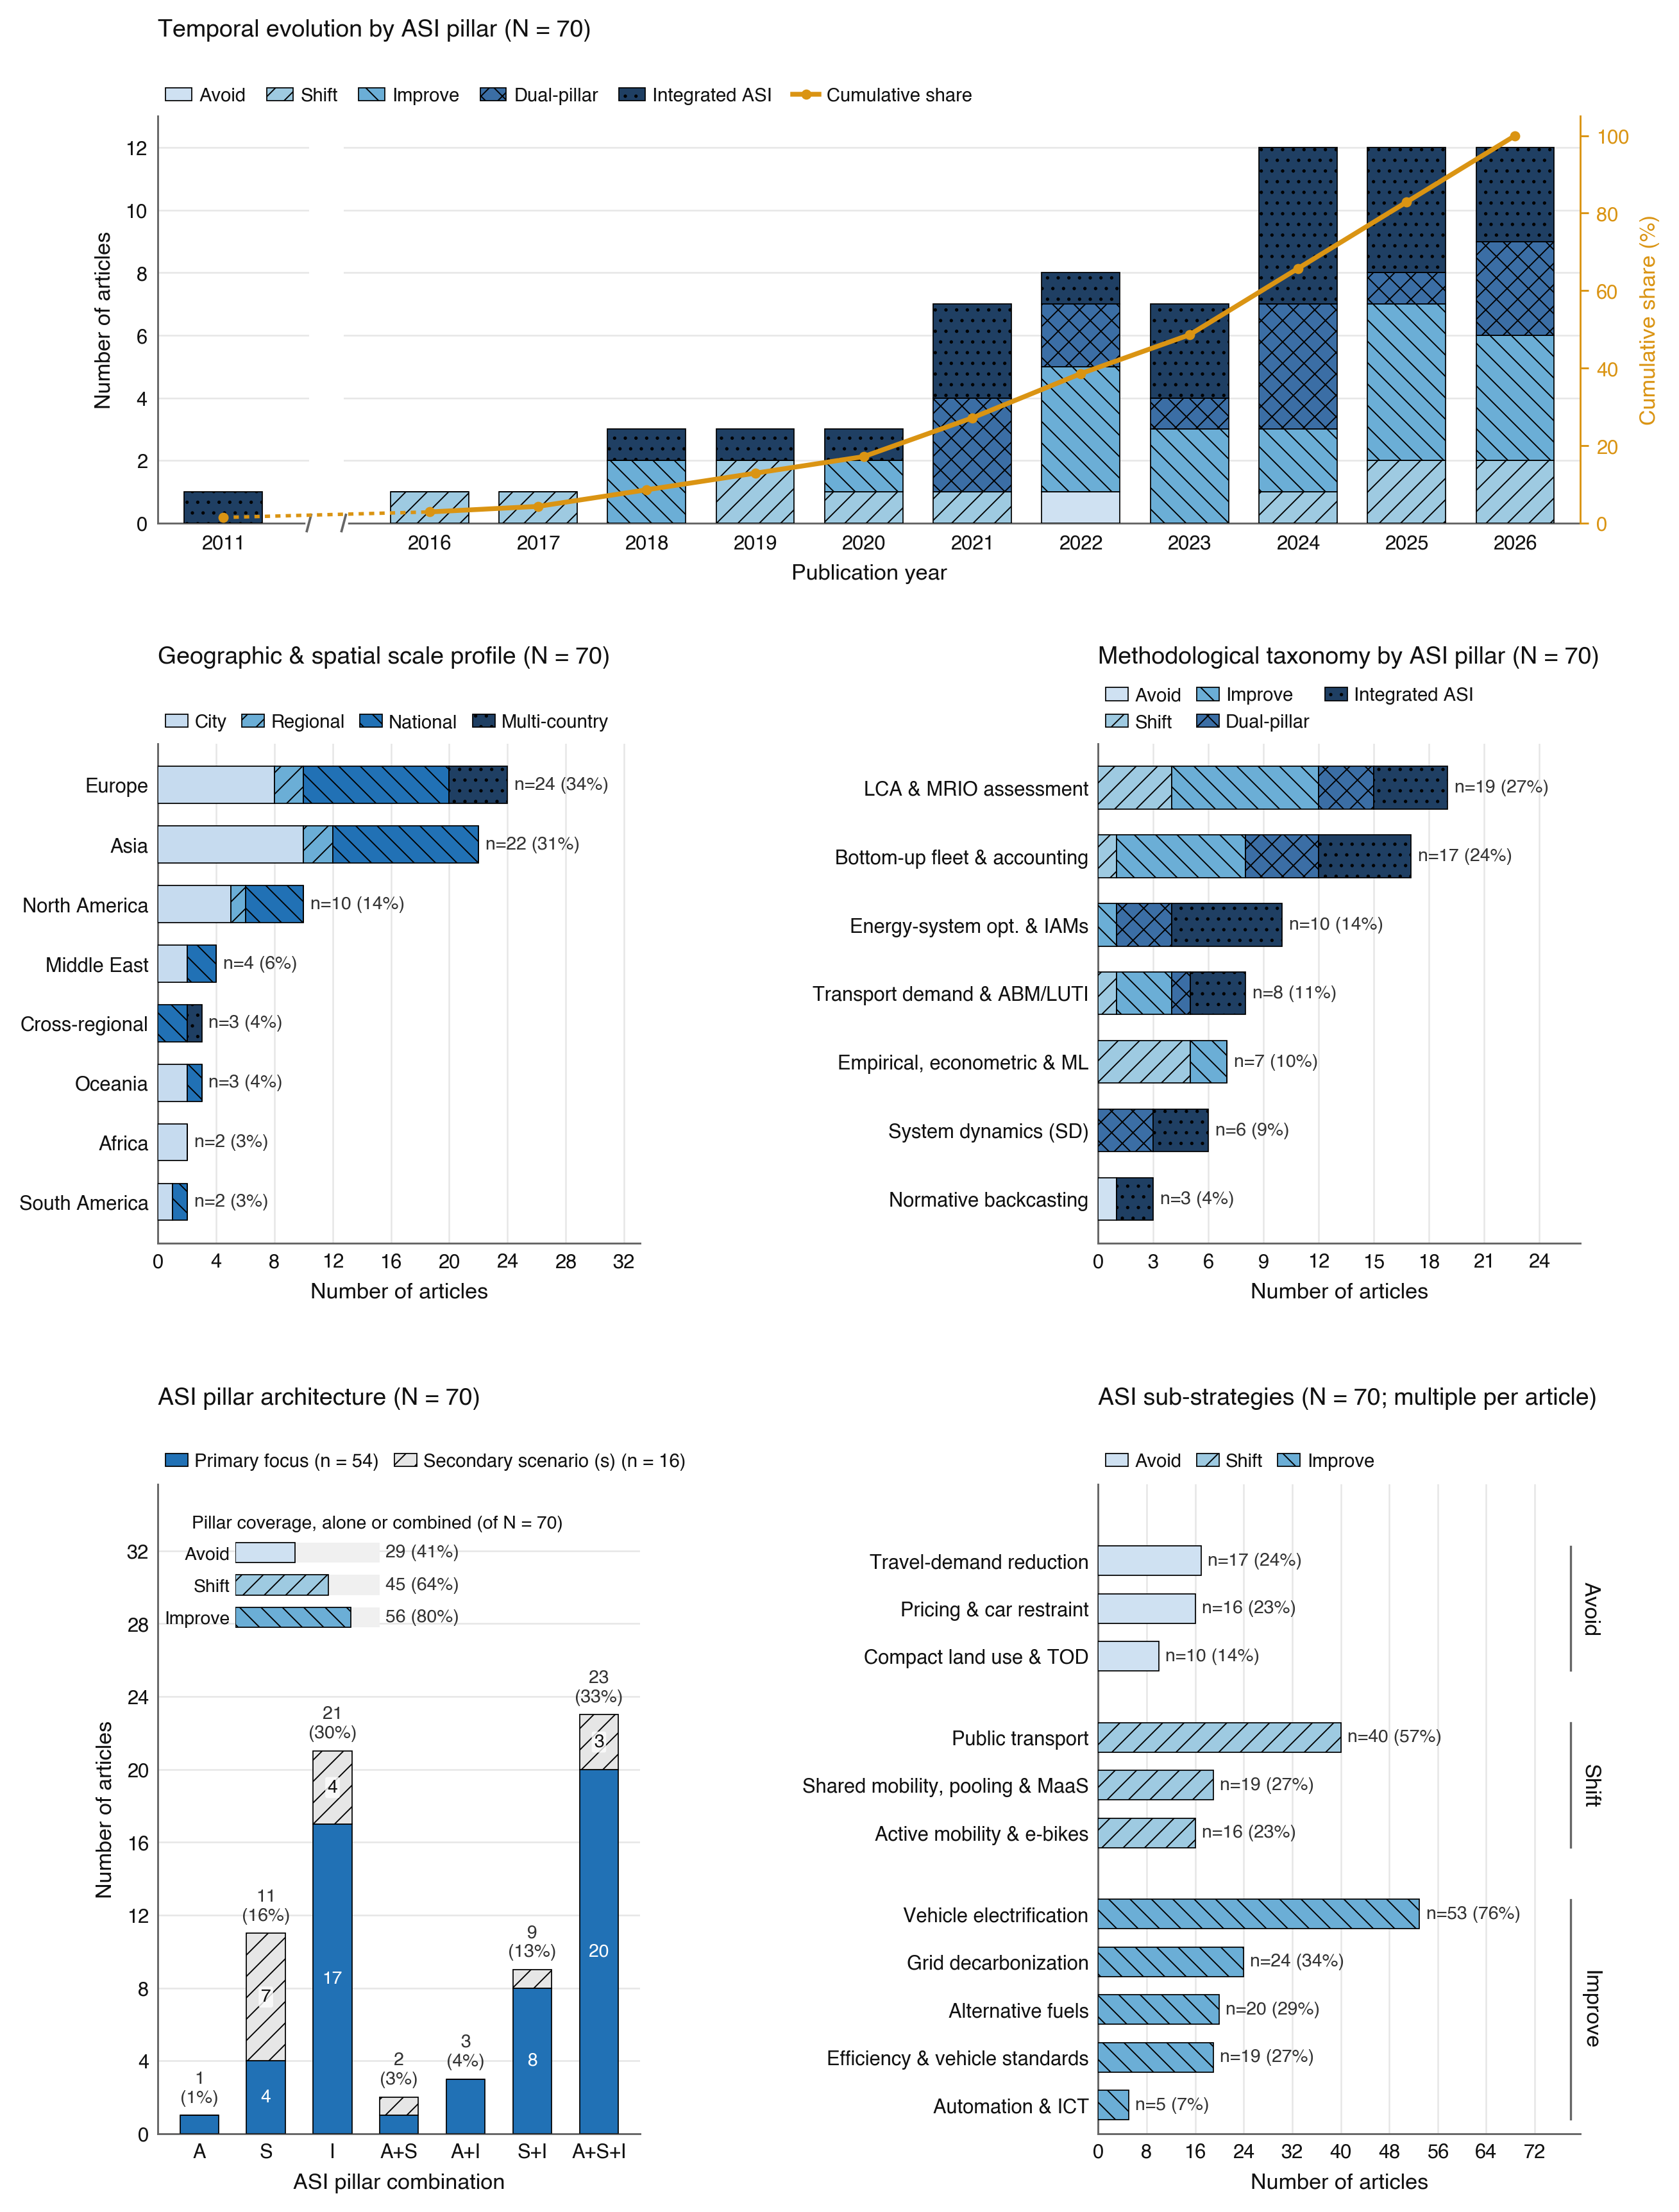

In [2]:
# %% [FIGURA EVIDENCE BASE – PÁGINA COMPLETA] Evolución temporal + geografía + métodos + arquitectura ASI + sub-estrategias (N = 70)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ==============================================================================
# 0. RUTAS Y PARÁMETROS
# ==============================================================================
DARK_MODE = False   # True -> versión sobre negro absoluto (#000000)
FS = 1.0            # Escala de TODAS las fuentes (súbelo para letras más grandes)
PANEL_C_VARIANT = 2  # Arquitectura ASI: 1 = eje y acotado a 24 (recuadro sobre fondo libre)
                     #                   2 = eje y completo con rejilla; anotación dentro del plot

# Tamaño pensado para una página A4 completa (\textwidth x ~\textheight menos el caption).
# Se dibuja a 8.4 in de ancho; en LaTeX se escala a 6.3 in (factor 0.75).
FIGSIZE = (8.4, 11.4)

INFILE = Path("/Users/joanpau/Documents/00_Inbox/SLR - Results Points/SLR Extraction Sheet.xlsx")
if not INFILE.exists():
    raise FileNotFoundError(f"No se encontró el archivo en: {INFILE}")

OUTDIR = INFILE.parent / "Images"
OUTDIR.mkdir(exist_ok=True)

df = pd.read_excel(INFILE, sheet_name="Extraction").dropna(subset=["ID"])
df["ID"] = df["ID"].astype(str).str.strip()
df["Year"] = pd.to_numeric(df["Year"], errors="raise").astype(int)
df["Is_secondary"] = df["Author"].astype(str).str.contains(r"\(s\)", regex=True)

N_TOTAL = len(df)
N_PRIM = int((~df["Is_secondary"]).sum())
N_SEC = int(df["Is_secondary"].sum())

# --- Mapeo de pilares ASI ---
ASI_5_ORDER = ["Avoid", "Shift", "Improve", "Dual-pillar", "Integrated ASI"]
PILLAR_5_MAP = {
    "A": "Avoid", "S": "Shift", "I": "Improve",
    "A+S": "Dual-pillar", "A+I": "Dual-pillar", "S+I": "Dual-pillar",
    "A+S+I": "Integrated ASI",
}
df["Pillar_5"] = df["Pillar"].astype(str).str.strip().map(PILLAR_5_MAP)

# --- Taxonomía metodológica completa (S01–S70) ---
METHOD_7_BY_ID = {
    **{k: "Bottom-up fleet & accounting" for k in [
        "S01", "S02", "S08", "S11", "S13", "S14", "S19", "S32", "S34",
        "S35", "S38", "S39", "S43", "S44", "S47", "S57", "S68"
    ]},
    **{k: "LCA & MRIO assessment" for k in [
        "S03", "S07", "S18", "S21", "S24", "S29", "S30", "S33", "S37",
        "S45", "S48", "S55", "S58", "S59", "S60", "S62", "S64", "S65", "S67"
    ]},
    **{k: "Energy-system opt. & IAMs" for k in [
        "S04", "S20", "S23", "S27", "S40", "S49", "S50", "S51", "S63", "S66"
    ]},
    **{k: "Transport demand & ABM/LUTI" for k in [
        "S05", "S22", "S31", "S36", "S42", "S52", "S56", "S61"
    ]},
    **{k: "System dynamics (SD)" for k in [
        "S12", "S15", "S17", "S25", "S53", "S54"
    ]},
    **{k: "Empirical, econometric & ML" for k in [
        "S06", "S09", "S16", "S41", "S46", "S69", "S70"
    ]},
    **{k: "Normative backcasting" for k in [
        "S10", "S26", "S28"
    ]},
}
df["Method_grp"] = df["ID"].map(METHOD_7_BY_ID)

# --- Clasificación geográfica completa (N = 70) ---
def classify_region(val):
    s = str(val).strip()
    if any(k in s for k in ["Netherlands, Sweden", "Brazil, India", "Japan, United Kingdom"]):
        return "Cross-regional"
    if any(k in s for k in ["China", "India", "Japan", "Singapore", "Taiwan", "Southeast Asia"]):
        return "Asia"
    if any(k in s for k in [
        "EU27", "Europe", "European", "Germany", "Hamburg", "Sweden", "UK", "United Kingdom",
        "Ireland", "Portugal", "Latvia", "Spain", "Antwerp", "Austria", "Poland"
    ]):
        return "Europe"
    if any(k in s for k in ["United States", "USA", "Canada", "Mexico"]):
        return "North America"
    if any(k in s for k in ["Qatar", "Iran", "Türkiye"]):
        return "Middle East"
    if any(k in s for k in ["Uganda", "Nigeria"]):
        return "Africa"
    if "Australia" in s:
        return "Oceania"
    if any(k in s for k in ["Argentina", "Colombia"]):
        return "South America"
    return "Other"

df["Region_grp"] = df["Region / country"].apply(classify_region)

# --- Sub-estrategias ASI (multi-etiqueta, codificadas a partir de la columna "Sub-strategy";
#     filas truncadas o erróneas completadas con Title/Notes). Cada estudio cuenta una vez
#     por sub-estrategia. La agrupación por pilar sigue la asignación convencional del marco
#     ASI, con independencia de la etiqueta de pilar del estudio. ---
SUBSTRATEGIES = {
    "A1": ("Avoid",   "Travel-demand reduction"),
    "A2": ("Avoid",   "Compact land use & TOD"),
    "A3": ("Avoid",   "Pricing & car restraint"),
    "S1": ("Shift",   "Public transport"),
    "S2": ("Shift",   "Active mobility & e-bikes"),
    "S3": ("Shift",   "Shared mobility, pooling & MaaS"),
    "I1": ("Improve", "Vehicle electrification"),
    "I2": ("Improve", "Grid decarbonization"),
    "I3": ("Improve", "Alternative fuels"),
    "I4": ("Improve", "Efficiency & vehicle standards"),
    "I5": ("Improve", "Automation & ICT"),
}
SUB_BY_ID = {
    "S01": "A1 S3 I1 I2",          "S02": "I1 I2 I4 I5",          "S03": "A1 S1 S2 S3 I1",
    "S04": "A1 S1 S2 S3 I1",       "S05": "I1 I4",                "S06": "S3",
    "S07": "S1 I1 I2 I3",          "S08": "I1 I2",                "S09": "S2",
    "S10": "A1 A2 S1 S2 I1 I2 I3 I4", "S11": "S1 I1 I3 I4",       "S12": "A1 S1 I1 I2 I3 I4",
    "S13": "A3 I1",                "S14": "A1 S1 I1",             "S15": "S1 S2 I1",
    "S16": "A3 S1 I1 I5",          "S17": "A3 S1",                "S18": "I1 I3",
    "S19": "A3 S1 S2 S3 I3 I4",    "S20": "A1 S1 S2 I1",          "S21": "S3 I1 I2 I3 I4",
    "S22": "I1 I2",                "S23": "I1 I3",                "S24": "S3 I1",
    "S25": "S1 I1 I3",             "S26": "A3 S3",                "S27": "S1 I1",
    "S28": "A1 A2 S1 S2 I1 I2 I3 I5", "S29": "I1 I3",             "S30": "I1 I2 I3 I4",
    "S31": "I1 I2 I5",             "S32": "A1 A2 S1 I4",          "S33": "A1 S1 I1 I2",
    "S34": "I1 I2",                "S35": "I1 I2 I3",             "S36": "A2 A3 S1 I4",
    "S37": "I1 I2 I4",             "S38": "S1 S2",                "S39": "A1 S1 S3 I1 I3 I4",
    "S40": "A3 S1 I1 I3",          "S41": "S1 I1",                "S42": "A1 A3 S1 I1",
    "S43": "I1 I2",                "S44": "A2 A3 S1",             "S45": "I1 I2",
    "S46": "I1 I2 I3",             "S47": "S1 I1 I3 I4",          "S48": "A2 A3 S1 S2 S3 I1 I2 I4",
    "S49": "A3 I1 I3",             "S50": "A1 A2 A3 S1 S3 I1 I3", "S51": "A1 A2 A3 S1 S3 I1 I3",
    "S52": "A2 S1 I1",             "S53": "A3 S1 I1",             "S54": "S1 S2 S3 I1 I4",
    "S55": "S1",                   "S56": "A1 A2 A3 S1 S2 S3",    "S57": "S1 S2 I1 I2 I4",
    "S58": "S1",                   "S59": "S3",                   "S60": "I1 I2",
    "S61": "S2",                   "S62": "A1 S1 S2 S3 I1 I2",    "S63": "A1 S1 S2 S3 I1 I4",
    "S64": "S1",                   "S65": "I1 I2",                "S66": "A3 S1 I1",
    "S67": "I1 I2 I4",             "S68": "I1 I4 I5",             "S69": "S3",
    "S70": "S1 S3",
}

# Aserciones de integridad
assert df["Pillar_5"].isna().sum() == 0, f"Pilares sin mapear: {df[df['Pillar_5'].isna()]['ID'].tolist()}"
assert df["Method_grp"].isna().sum() == 0, f"Métodos sin mapear: {df[df['Method_grp'].isna()]['ID'].tolist()}"
assert (df["Region_grp"] == "Other").sum() == 0, f"Regiones sin mapear: {df[df['Region_grp'] == 'Other']['Region / country'].tolist()}"
assert set(SUB_BY_ID) == set(df["ID"]), f"Sub-estrategias sin codificar: {sorted(set(df['ID']) - set(SUB_BY_ID))}"
assert all(c in SUBSTRATEGIES for v in SUB_BY_ID.values() for c in v.split())

sub_long = pd.DataFrame(
    [(sid, c, *SUBSTRATEGIES[c]) for sid, v in SUB_BY_ID.items() for c in v.split()],
    columns=["ID", "Code", "Sub_pillar", "Sub_strategy"],
).merge(df[["ID", "Author", "Year", "Pillar", "Pillar_5", "Sub-strategy"]], on="ID")

# ==============================================================================
# 1. PALETAS Y TIPOGRAFÍA EDITORIAL (LIGHT / DARK)
# ==============================================================================
BG_COL    = "#000000" if DARK_MODE else "#FFFFFF"
FG_COL    = "#FFFFFF" if DARK_MODE else "#111111"
SUB_COL   = "#D9D9D9" if DARK_MODE else "#333333"
EDGE_COL  = "#FFFFFF" if DARK_MODE else "#000000"
GRID_COL  = "#222222" if DARK_MODE else "0.90"
SPINE_COL = "#888888" if DARK_MODE else "0.40"
CUM_COL   = "#f2be54" if DARK_MODE else "#da9413"   # oro del paper (cuota acumulada)

ASI_5_COLORS = dict(zip(
    ASI_5_ORDER,
    ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#2b5c8f" if DARK_MODE else "#1f3f63"]
))
ASI_5_HATCHES = dict(zip(ASI_5_ORDER, ["", "///", "\\\\\\", "xxx", "..."]))

SCALE_ORDER = ["City", "Regional", "National", "Multi-country"]
SCALE_COLORS = {
    "City":          "#c6dbef",
    "Regional":      "#6baed6",
    "National":      "#2171b5",
    "Multi-country": "#2b5c8f" if DARK_MODE else "#1f3f63",
}
SCALE_HATCHES = {"City": "", "Regional": "///", "National": "\\\\\\", "Multi-country": "..."}

# Tamaños de letra (todos escalan con FS)
F_TITLE, F_LABEL, F_TICK, F_LEG, F_ANN = 9.0 * FS, 8.2 * FS, 7.4 * FS, 7.0 * FS, 6.8 * FS
TITLE_PAD = 30 * FS

plt.rcParams.update({
    "font.family":       "sans-serif",
    "font.sans-serif":   ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size":         F_TICK,
    "axes.labelsize":    F_LABEL,
    "axes.titlesize":    F_TITLE,
    "xtick.labelsize":   F_TICK,
    "ytick.labelsize":   F_TICK,
    "legend.fontsize":   F_LEG,
    "axes.linewidth":    0.7,
    "hatch.linewidth":   0.45,
    "hatch.color":       EDGE_COL,
    "figure.facecolor":  BG_COL,
    "axes.facecolor":    BG_COL,
    "savefig.facecolor": BG_COL,
    "text.color":        FG_COL,
    "axes.labelcolor":   FG_COL,
    "xtick.color":       FG_COL,
    "ytick.color":       FG_COL,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
})

def style_ax(ax, grid_axis="y"):
    ax.set_facecolor(BG_COL)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(SPINE_COL)
    ax.spines["bottom"].set_color(SPINE_COL)
    if grid_axis == "y":
        ax.yaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    elif grid_axis == "x":
        ax.xaxis.grid(True, color=GRID_COL, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=FG_COL)

def style_legend(leg):
    for patch in leg.get_patches():
        patch.set_linewidth(0.42)
        patch.set_edgecolor(EDGE_COL)

def panel_title(ax, text):
    ax.set_title(text, fontsize=F_TITLE, fontweight="bold", pad=TITLE_PAD, loc="left", color=FG_COL)

def top_legend(ax, ncol, **kw):
    leg = ax.legend(ncol=ncol, frameon=False, fontsize=F_LEG, handlelength=1.2,
                    columnspacing=0.8, handletextpad=0.35, labelcolor=FG_COL,
                    loc="lower left", bbox_to_anchor=(0.0, 1.01), borderaxespad=0, **kw)
    style_legend(leg)
    return leg

# ==============================================================================
# 2. MAQUETACIÓN: fila superior a todo el ancho + rejilla 2x2
# ==============================================================================
fig = plt.figure(figsize=FIGSIZE, dpi=300, facecolor=BG_COL)
outer = gridspec.GridSpec(3, 1, figure=fig, height_ratios=[0.80, 1.0, 1.30], hspace=0.42,
                          left=0.06, right=0.94, top=0.97, bottom=0.05)
ax_t = fig.add_subplot(outer[0])
grid = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=outer[1:], height_ratios=[1.0, 1.30],
                                        hspace=0.42, wspace=0.95)
ax_a = fig.add_subplot(grid[0, 0])
ax_b = fig.add_subplot(grid[0, 1])
ax_c = fig.add_subplot(grid[1, 0])
ax_d = fig.add_subplot(grid[1, 1])

# ------------------------------------------------------------------------------
# PANEL SUPERIOR: Evolución temporal por pilar ASI + cuota acumulada (eje con corte)
# ------------------------------------------------------------------------------
BREAK_YEARS = range(2012, 2016)   # años sin publicaciones que se omiten
GAP = 0.9                         # anchura del hueco del corte (en "años" de eje)

yr0, yr1 = int(df["Year"].min()), int(df["Year"].max())
M_year = (pd.crosstab(df["Year"], df["Pillar_5"])
            .reindex(columns=ASI_5_ORDER, fill_value=0)
            .reindex(range(yr0, yr1 + 1), fill_value=0))
total_per_year = M_year.sum(axis=1)
cum_share = 100 * total_per_year.cumsum() / total_per_year.sum()
assert total_per_year.reindex(BREAK_YEARS, fill_value=0).sum() == 0, "BREAK_YEARS contiene publicaciones"

years = [y for y in M_year.index if y not in BREAK_YEARS]
x_t = np.arange(len(years), dtype=float)
x_t[np.array(years) > max(BREAK_YEARS)] += GAP
M_year, total_per_year, cum_share = M_year.loc[years], total_per_year.loc[years], cum_share.loc[years]
i_before = years.index(min(BREAK_YEARS) - 1)
x_break = (x_t[i_before] + x_t[i_before + 1]) / 2

bottom_t = np.zeros(len(years))
for p in ASI_5_ORDER:
    vals = M_year[p].values
    ax_t.bar(x_t, vals, bottom=bottom_t, width=0.72, label=p, color=ASI_5_COLORS[p],
             edgecolor=EDGE_COL, linewidth=0.42, hatch=ASI_5_HATCHES[p], zorder=3)
    bottom_t += vals

ax_t.set_ylabel("Number of articles", fontsize=F_LABEL)
ax_t.set_xlabel("Publication year", fontsize=F_LABEL)
ax_t.set_xticks(x_t)
ax_t.set_xticklabels([str(y) for y in years])
ax_t.yaxis.set_major_locator(MaxNLocator(integer=True))
ax_t.set_ylim(0, total_per_year.max() + 1)
ax_t.set_xlim(x_t[0] - 0.6, x_t[-1] + 0.6)
style_ax(ax_t, grid_axis="y")
ax_t.tick_params(pad=4)
panel_title(ax_t, f"Temporal evolution by ASI pillar (N = {N_TOTAL})")

# Marca de corte (//) en el eje X
half = 0.16
trans = ax_t.get_xaxis_transform()
ax_t.axvspan(x_break - half, x_break + half, color=BG_COL, zorder=1, linewidth=0)
ax_t.plot([x_break - half, x_break + half], [0, 0], color=BG_COL, linewidth=3,
          transform=trans, clip_on=False, zorder=5)
for dx in (-half, half):
    ax_t.plot([x_break + dx - 0.02, x_break + dx + 0.02], [-0.02, 0.02], color=SPINE_COL,
              linewidth=0.9, transform=trans, clip_on=False, zorder=6)

# Eje derecho: cuota acumulada
ax_t2 = ax_t.twinx()
pre, post = slice(0, i_before + 1), slice(i_before + 1, None)
kw = dict(color=CUM_COL, linewidth=1.8, zorder=4)
ax_t2.plot(x_t[pre], cum_share.values[pre], **kw)
ax_t2.plot(x_t[post], cum_share.values[post], **kw)
ax_t2.plot(x_t[i_before:i_before + 2], cum_share.values[i_before:i_before + 2], color=CUM_COL,
           linewidth=1.3, linestyle=(0, (1.5, 1.5)), zorder=4)
ax_t2.plot(x_t, cum_share.values, linestyle="none", marker="o", markersize=3.8, color=CUM_COL,
           markeredgewidth=0, zorder=5)
ax_t2.set_ylim(0, 105)
ax_t2.set_yticks(range(0, 101, 20))
ax_t2.set_ylabel("Cumulative share (%)", fontsize=F_LABEL, color=CUM_COL)
ax_t2.tick_params(axis="y", labelsize=F_TICK, direction="out", length=3, width=0.7, pad=3,
                  colors=CUM_COL)
for s in ["top", "left", "bottom"]:
    ax_t2.spines[s].set_visible(False)
ax_t2.spines["right"].set_color(CUM_COL)

handles_t, labels_t = ax_t.get_legend_handles_labels()
handles_t.append(Line2D([0], [0], color=CUM_COL, linewidth=1.8, marker="o", markersize=3.8,
                        markeredgewidth=0))
labels_t.append("Cumulative share")
leg_t = ax_t.legend(handles_t, labels_t, ncol=len(labels_t), frameon=False, fontsize=F_LEG,
                    handlelength=1.4, handletextpad=0.4, columnspacing=1.1, labelcolor=FG_COL,
                    loc="lower left", bbox_to_anchor=(0.0, 1.01), borderaxespad=0)
style_legend(leg_t)

# ------------------------------------------------------------------------------
# PANEL: Perfil geográfico y escala espacial
# ------------------------------------------------------------------------------
reg_order = df["Region_grp"].value_counts().index.tolist()[::-1]
M_geo = (pd.crosstab(df["Region_grp"], df["Scale"].astype(str).str.strip())
           .reindex(index=reg_order, columns=SCALE_ORDER, fill_value=0))

y_geo = np.arange(len(reg_order))
left_a = np.zeros(len(reg_order))
for sc in SCALE_ORDER:
    vals = M_geo[sc].values
    ax_a.barh(y_geo, vals, left=left_a, height=0.62, color=SCALE_COLORS[sc], edgecolor=EDGE_COL,
              linewidth=0.42, hatch=SCALE_HATCHES[sc], label=sc, zorder=3)
    left_a += vals
for yi, tot in enumerate(left_a):
    ax_a.text(tot + max(left_a) * 0.02, yi, f"n={int(tot)} ({100 * tot / N_TOTAL:.0f}%)",
              va="center", ha="left", fontsize=F_ANN, color=SUB_COL)

ax_a.set_yticks(y_geo)
ax_a.set_yticklabels(reg_order, fontweight="bold")
ax_a.set_xlabel("Number of articles", fontsize=F_LABEL)
ax_a.set_xlim(0, max(left_a) * 1.38)
ax_a.xaxis.set_major_locator(MaxNLocator(integer=True))
style_ax(ax_a, grid_axis="x")
panel_title(ax_a, f"Geographic & spatial scale profile (N = {N_TOTAL})")
top_legend(ax_a, ncol=4)

# ------------------------------------------------------------------------------
# PANEL: Taxonomía metodológica por pilar ASI
# ------------------------------------------------------------------------------
meth_order = df["Method_grp"].value_counts().index.tolist()[::-1]
M_meth = (pd.crosstab(df["Method_grp"], df["Pillar_5"])
            .reindex(index=meth_order, columns=ASI_5_ORDER, fill_value=0))

y_meth = np.arange(len(meth_order))
left_b = np.zeros(len(meth_order))
for p in ASI_5_ORDER:
    vals = M_meth[p].values
    ax_b.barh(y_meth, vals, left=left_b, height=0.62, color=ASI_5_COLORS[p], edgecolor=EDGE_COL,
              linewidth=0.42, hatch=ASI_5_HATCHES[p], label=p, zorder=3)
    left_b += vals
for yi, tot in enumerate(left_b):
    ax_b.text(tot + max(left_b) * 0.02, yi, f"n={int(tot)} ({100 * tot / N_TOTAL:.0f}%)",
              va="center", ha="left", fontsize=F_ANN, color=SUB_COL)

ax_b.set_yticks(y_meth)
ax_b.set_yticklabels(meth_order, fontweight="bold")
ax_b.set_xlabel("Number of articles", fontsize=F_LABEL)
ax_b.set_xlim(0, max(left_b) * 1.38)
ax_b.xaxis.set_major_locator(MaxNLocator(integer=True))
style_ax(ax_b, grid_axis="x")
panel_title(ax_b, f"Methodological taxonomy by ASI pillar (N = {N_TOTAL})")
top_legend(ax_b, ncol=3)

# ------------------------------------------------------------------------------
# PANEL: Arquitectura de combinaciones de pilares ASI (búsqueda primaria vs (s))
# ------------------------------------------------------------------------------
PILLAR_7_ORDER = ["A", "S", "I", "A+S", "A+I", "S+I", "A+S+I"]
pill = df["Pillar"].astype(str).str.strip()
prim_counts = pill[~df["Is_secondary"]].value_counts().reindex(PILLAR_7_ORDER, fill_value=0).values
sec_counts  = pill[df["Is_secondary"]].value_counts().reindex(PILLAR_7_ORDER, fill_value=0).values

x_p7 = np.arange(len(PILLAR_7_ORDER))
col_prim_c = "#2b7bba" if DARK_MODE else "#2171b5"
col_sec_c  = "#262626" if DARK_MODE else "#e6e6e6"

ax_c.bar(x_p7, prim_counts, width=0.58, color=col_prim_c, edgecolor=EDGE_COL,
         linewidth=0.42, label=f"Primary focus (n = {N_PRIM})", zorder=3)
ax_c.bar(x_p7, sec_counts, bottom=prim_counts, width=0.58, color=col_sec_c,
         edgecolor=EDGE_COL, linewidth=0.42, hatch="///",
         label=f"Secondary scenario (s) (n = {N_SEC})", zorder=3)

totals_c = prim_counts + sec_counts
for xi, (pr, sc, tot) in enumerate(zip(prim_counts, sec_counts, totals_c)):
    ax_c.text(xi, tot + max(totals_c) * 0.022, f"{tot}\n({100 * tot / N_TOTAL:.0f}%)",
              ha="center", va="bottom", fontsize=F_ANN, fontweight="bold", color=SUB_COL)
    if pr >= 3 and sc > 0:
        ax_c.text(xi, pr / 2, f"{pr}", ha="center", va="center",
                  fontsize=F_ANN, fontweight="bold", color="#FFFFFF", zorder=4)
    if sc >= 3:
        ax_c.text(xi, pr + sc / 2, f"{sc}", ha="center", va="center",
                  fontsize=F_ANN, fontweight="bold", color=FG_COL, zorder=4,
                  bbox=dict(boxstyle="round,pad=0.12", facecolor=BG_COL, edgecolor="none", alpha=0.8))

ax_c.set_xticks(x_p7)
ax_c.set_xticklabels(PILLAR_7_ORDER, fontweight="bold")
ax_c.set_xlabel("ASI pillar combination", fontsize=F_LABEL)
ax_c.set_ylabel("Number of articles", fontsize=F_LABEL)
ax_c.set_ylim(0, max(totals_c) * 1.55)
if PANEL_C_VARIANT == 1:
    y_top_c = int(np.ceil(max(totals_c) / 4) * 4)           # último tick útil (24)
    ax_c.set_yticks(range(0, y_top_c + 1, 4))
    style_ax(ax_c, grid_axis="y")
    ax_c.spines["left"].set_bounds(0, y_top_c)              # eje y acotado: deja libre el recuadro
else:
    ax_c.yaxis.set_major_locator(MaxNLocator(integer=True))  # eje y completo (0–32) con rejilla
    style_ax(ax_c, grid_axis="y")
panel_title(ax_c, f"ASI pillar architecture (N = {N_TOTAL})")
top_legend(ax_c, ncol=2)

# Recuadro de cobertura: artículos que evalúan cada pilar, solo o combinado (barra sobre N total)
pillar_any = {p: int(pill.str.contains(p[0]).sum()) for p in ["Avoid", "Shift", "Improve"]}
TRACK_COL = "#1a1a1a" if DARK_MODE else "#f0f0f0"
ax_in = ax_c.inset_axes([0.16, 0.77, 0.30, 0.15])
for i, (p, n) in enumerate(list(pillar_any.items())[::-1]):
    ax_in.barh(i, N_TOTAL, height=0.62, color=TRACK_COL, edgecolor="none", zorder=1)
    ax_in.barh(i, n, height=0.62, color=ASI_5_COLORS[p], edgecolor=EDGE_COL, linewidth=0.42,
               hatch=ASI_5_HATCHES[p], zorder=2)
    ax_in.text(N_TOTAL * 1.04, i, f"{n} ({100 * n / N_TOTAL:.0f}%)", va="center", ha="left",
               fontsize=F_ANN, color=SUB_COL)
ax_in.set_yticks(range(3))
ax_in.set_yticklabels(list(pillar_any)[::-1], fontsize=F_ANN, color=FG_COL)
ax_in.set_xlim(0, N_TOTAL)
ax_in.set_ylim(-0.5, 2.5)
ax_in.set_xticks([])
ax_in.tick_params(length=0, pad=2)
for s in ax_in.spines.values():
    s.set_visible(False)
ax_in.set_facecolor("none")
COV_TITLE = (f"Pillar coverage, alone or combined (n of {N_TOTAL})" if PANEL_C_VARIANT == 1
             else f"Pillar coverage, alone or combined (of N = {N_TOTAL})")
ax_in.set_title(COV_TITLE, fontsize=F_ANN,
                color=FG_COL, loc="left", pad=3, x=-0.30)

# ------------------------------------------------------------------------------
# PANEL: Sub-estrategias ASI (artículos que evalúan cada sub-estrategia)
# ------------------------------------------------------------------------------
SUB_PILLARS = ["Avoid", "Shift", "Improve"]
sub_counts = sub_long.groupby("Code")["ID"].nunique()

rows, y_pos, y = [], [], 0.0
group_spans = {}
for gp in SUB_PILLARS[::-1]:                       # Improve abajo, Avoid arriba
    codes = sorted([c for c, (p, _) in SUBSTRATEGIES.items() if p == gp],
                   key=lambda c: sub_counts.get(c, 0))
    start = y
    for c in codes:
        rows.append(c)
        y_pos.append(y)
        y += 1.0
    group_spans[gp] = (start, y - 1.0)
    y += 0.7

vals_d = np.array([sub_counts.get(c, 0) for c in rows])
for c, yi, v in zip(rows, y_pos, vals_d):
    gp = SUBSTRATEGIES[c][0]
    ax_d.barh(yi, v, height=0.62, color=ASI_5_COLORS[gp], edgecolor=EDGE_COL,
              linewidth=0.42, hatch=ASI_5_HATCHES[gp], zorder=3)
    ax_d.text(v + vals_d.max() * 0.02, yi, f"n={v} ({100 * v / N_TOTAL:.0f}%)",
              va="center", ha="left", fontsize=F_ANN, color=SUB_COL)

ax_d.set_yticks(y_pos)
ax_d.set_yticklabels([SUBSTRATEGIES[c][1] for c in rows])
ax_d.set_ylim(-0.6, y - 0.1)
ax_d.set_xlabel("Number of articles", fontsize=F_LABEL)
ax_d.set_xlim(0, vals_d.max() * 1.50)
ax_d.xaxis.set_major_locator(MaxNLocator(integer=True))
style_ax(ax_d, grid_axis="x")
panel_title(ax_d, f"ASI sub-strategies (N = {N_TOTAL}; multiple per article)")

for gp, (y0, y1) in group_spans.items():
    xb = vals_d.max() * 1.47
    ax_d.plot([xb, xb], [y0 - 0.3, y1 + 0.3], color=SPINE_COL, lw=0.8, zorder=4, clip_on=False)
    ax_d.text(xb + vals_d.max() * 0.03, (y0 + y1) / 2, gp, rotation=270, va="center", ha="left",
              fontsize=F_LABEL, fontweight="bold", color=FG_COL, clip_on=False)

handles_d = [Patch(facecolor=ASI_5_COLORS[p], edgecolor=EDGE_COL, linewidth=0.42,
                   hatch=ASI_5_HATCHES[p], label=p) for p in SUB_PILLARS]
top_legend(ax_d, ncol=3, handles=handles_d)

# ==============================================================================
# 3. EXPORTACIÓN
# ==============================================================================
suffix = ("_v2" if PANEL_C_VARIANT == 2 else "") + ("_dark" if DARK_MODE else "")
stem = f"fig_evidence_base_fullpage{N_TOTAL}{suffix}"
for ext in ["pdf", "png", "svg"]:
    fig.savefig(OUTDIR / f"{stem}.{ext}", dpi=600 if ext == "png" else 300,
                bbox_inches="tight", pad_inches=0.04, facecolor=BG_COL, edgecolor="none")
sub_long.to_csv(OUTDIR / "substrategy_coding_all70.csv", index=False)

print(f"Exportación completada (N = {N_TOTAL}; primarios = {N_PRIM}; secundarios (s) = {N_SEC})")
print(f"Archivos guardados en: {OUTDIR}/{stem}.{{pdf,png,svg}}")
plt.show()